#Input Gambar & Display

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def show_images(titles, images, figsize=(15, 5)):
    n = len(images)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i+1)
        plt.imshow(images[i], cmap='gray' if len(images[i].shape) == 2 else None)
        plt.title(titles[i])
        plt.axis('off')
    plt.show()

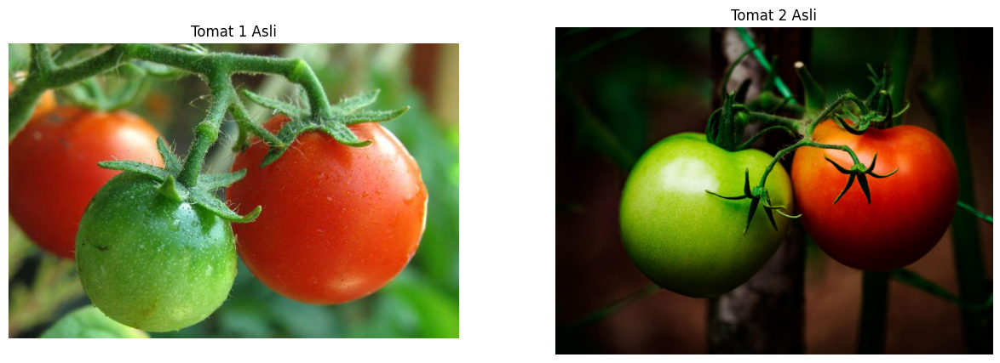

In [ ]:
img_tomat1_bgr = cv2.imread('tomat1.jpg')
img_tomat2_bgr = cv2.imread('tomat2.jpg')

img_tomat1 = cv2.cvtColor(img_tomat1_bgr, cv2.COLOR_BGR2RGB)
img_tomat2 = cv2.cvtColor(img_tomat2_bgr, cv2.COLOR_BGR2RGB)

show_images(['Tomat 1 Asli', 'Tomat 2 Asli'], [img_tomat1, img_tomat2])

# Smoothing

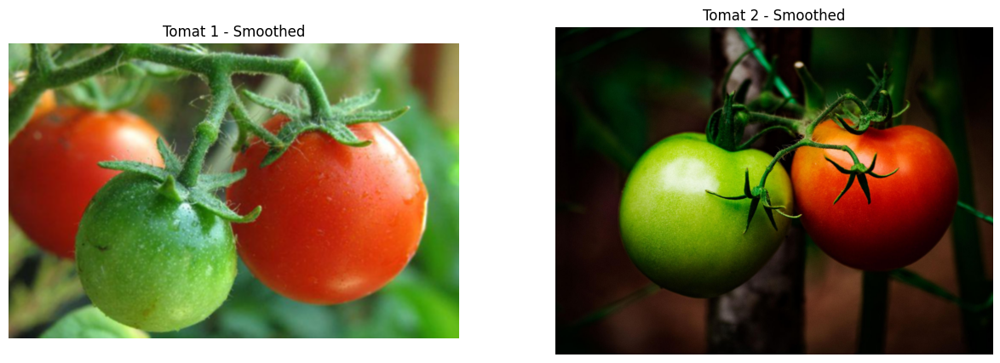

In [ ]:
# Ukuran kernel tergantung besaran noise
smoothed_only_tomat1 = cv2.GaussianBlur(img_tomat1, (3, 3), 0)
smoothed_only_tomat2 = cv2.GaussianBlur(img_tomat2, (3, 3), 0)

show_images(['Tomat 1 - Smoothed', 'Tomat 2 - Smoothed'], [smoothed_only_tomat1, smoothed_only_tomat2])

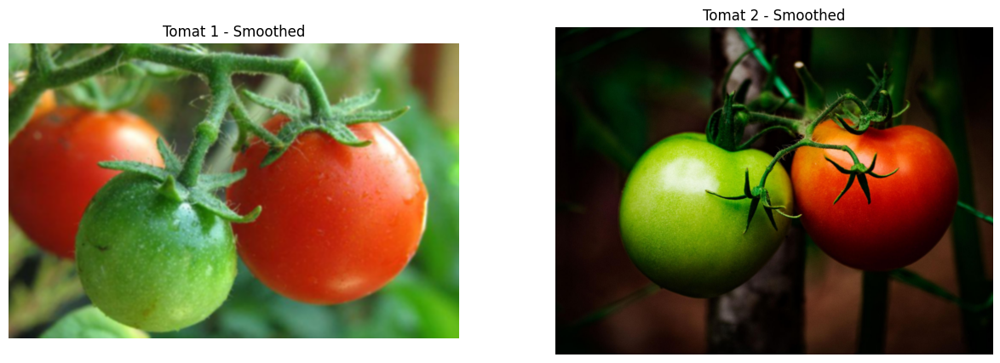

In [ ]:
# Ukuran kernel tergantung besaran noise
smoothed_only_tomat1 = cv2.GaussianBlur(img_tomat1, (5, 5), 0)
smoothed_only_tomat2 = cv2.GaussianBlur(img_tomat2, (5, 5), 0)

show_images(['Tomat 1 - Smoothed', 'Tomat 2 - Smoothed'], [smoothed_only_tomat1, smoothed_only_tomat2])

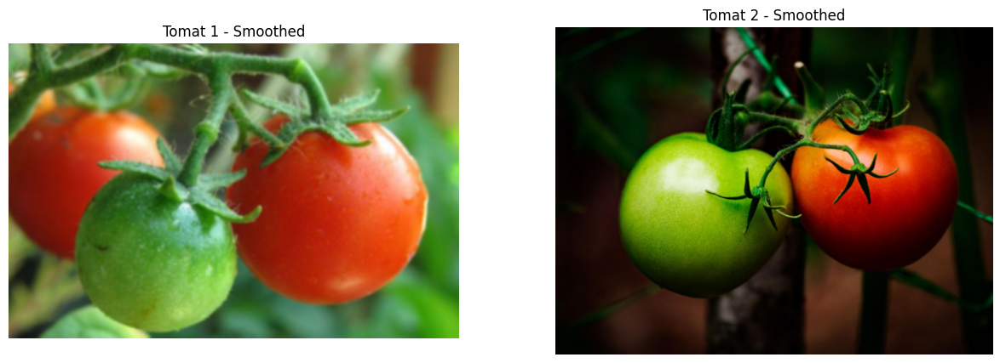

In [ ]:
# Ukuran kernel tergantung besaran noise
smoothed_only_tomat1 = cv2.GaussianBlur(img_tomat1, (7, 7), 0)
smoothed_only_tomat2 = cv2.GaussianBlur(img_tomat2, (7, 7), 0)

show_images(['Tomat 1 - Smoothed', 'Tomat 2 - Smoothed'], [smoothed_only_tomat1, smoothed_only_tomat2])

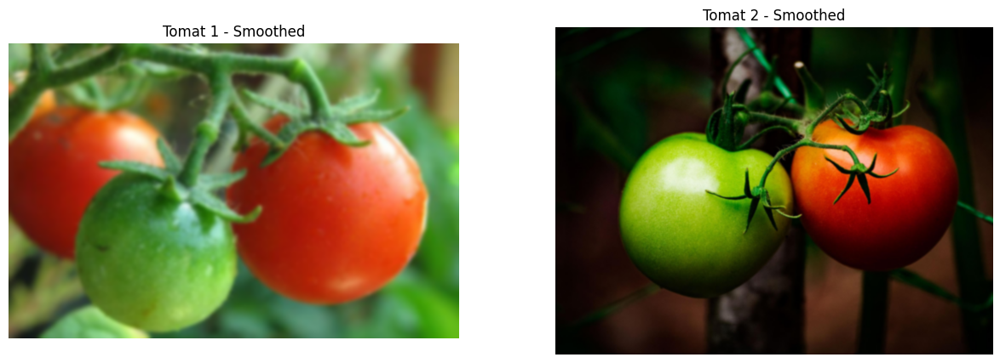

In [ ]:
# Ukuran kernel tergantung besaran noise
smoothed_only_tomat1 = cv2.GaussianBlur(img_tomat1, (13, 13), 0)
smoothed_only_tomat2 = cv2.GaussianBlur(img_tomat2, (13, 13), 0)

show_images(['Tomat 1 - Smoothed', 'Tomat 2 - Smoothed'], [smoothed_only_tomat1, smoothed_only_tomat2])

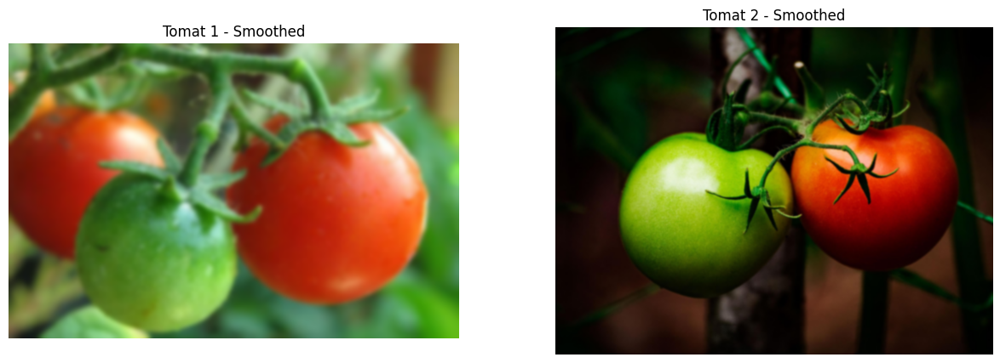

In [ ]:
# Ukuran kernel tergantung besaran noise
smoothed_only_tomat1 = cv2.GaussianBlur(img_tomat1, (17, 17), 0)
smoothed_only_tomat2 = cv2.GaussianBlur(img_tomat2, (17, 17), 0)

show_images(['Tomat 1 - Smoothed', 'Tomat 2 - Smoothed'], [smoothed_only_tomat1, smoothed_only_tomat2])

#Sharpening

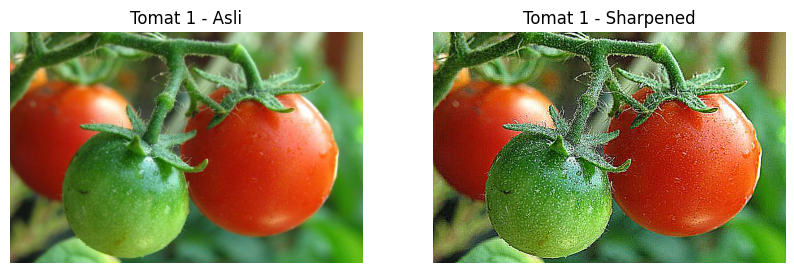

In [ ]:
# kernel Laplacian kustom
kernel_sharpening = np.array([[-1, -1, -1],
                              [-1,  9, -1],
                              [-1, -1, -1]])

sharpened_only_tomat1 = cv2.filter2D(img_tomat1, -1, kernel_sharpening)
sharpened_only_tomat2 = cv2.filter2D(img_tomat2, -1, kernel_sharpening)

show_images(['Tomat 1 - Asli', 'Tomat 1 - Sharpened'], [img_tomat1, sharpened_only_tomat1], figsize=(10, 5))

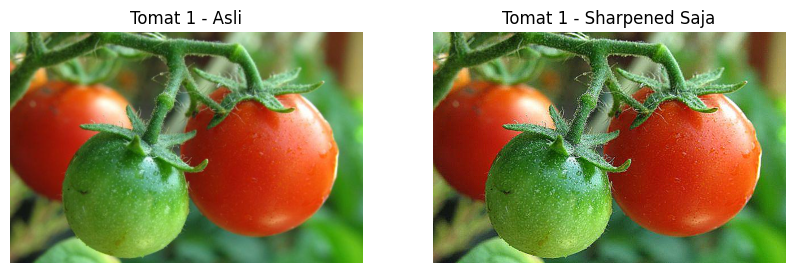

In [ ]:
kernel_sharpening = np.array([[ 0, -1,  0],
                              [-1,  5, -1],
                              [ 0, -1,  0]])

sharpened_only_tomat1 = cv2.filter2D(img_tomat1, -1, kernel_sharpening)
sharpened_only_tomat2 = cv2.filter2D(img_tomat2, -1, kernel_sharpening)

show_images(['Tomat 1 - Asli', 'Tomat 1 - Sharpened Saja'], [img_tomat1, sharpened_only_tomat1], figsize=(10, 5))

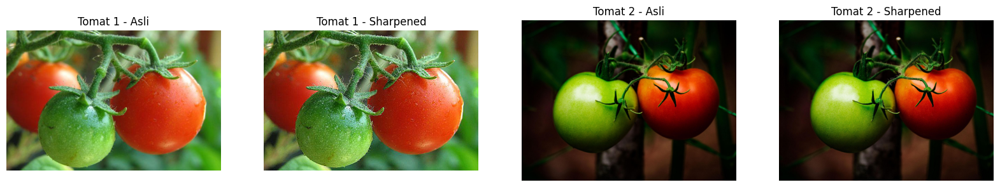

In [ ]:
kernel_sharpening = np.array([[ 0, -1,  0],
                              [-1,  5, -1],
                              [ 0, -1,  0]])

sharpened_only_tomat1 = cv2.filter2D(img_tomat1, -1, kernel_sharpening)
sharpened_only_tomat2 = cv2.filter2D(img_tomat2, -1, kernel_sharpening)

show_images(
    ['Tomat 1 - Asli', 'Tomat 1 - Sharpened', 'Tomat 2 - Asli', 'Tomat 2 - Sharpened'],
    [img_tomat1, sharpened_only_tomat1, img_tomat2, sharpened_only_tomat2],
    figsize=(20, 5)
)

# Smoothing + Sharpening

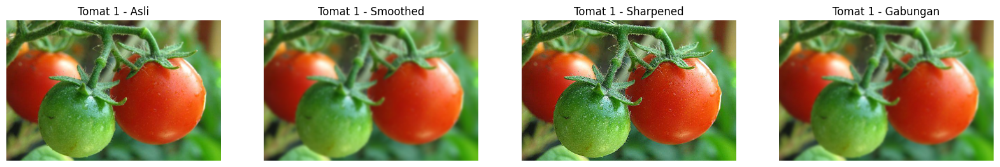

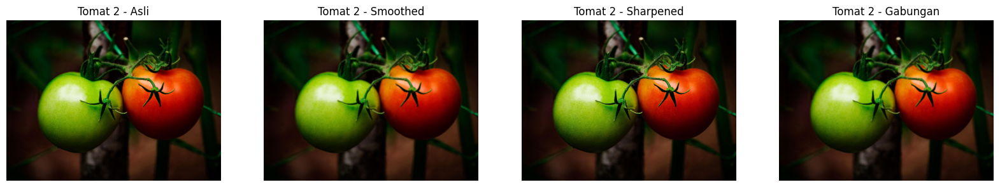

In [ ]:
combined_tomat1 = cv2.filter2D(smoothed_only_tomat1, -1, kernel_sharpening)
combined_tomat2 = cv2.filter2D(smoothed_only_tomat2, -1, kernel_sharpening)

show_images(
    ['Tomat 1 - Asli', 'Tomat 1 - Smoothed', 'Tomat 1 - Sharpened', 'Tomat 1 - Gabungan'],
    [img_tomat1, smoothed_only_tomat1, sharpened_only_tomat1, combined_tomat1],
    figsize=(20, 5)
)

show_images(
    ['Tomat 2 - Asli', 'Tomat 2 - Smoothed', 'Tomat 2 - Sharpened', 'Tomat 2 - Gabungan'],
    [img_tomat2, smoothed_only_tomat2, sharpened_only_tomat2, combined_tomat2],
    figsize=(20, 5)
)

# Segmentasi

## K-Means Clustering

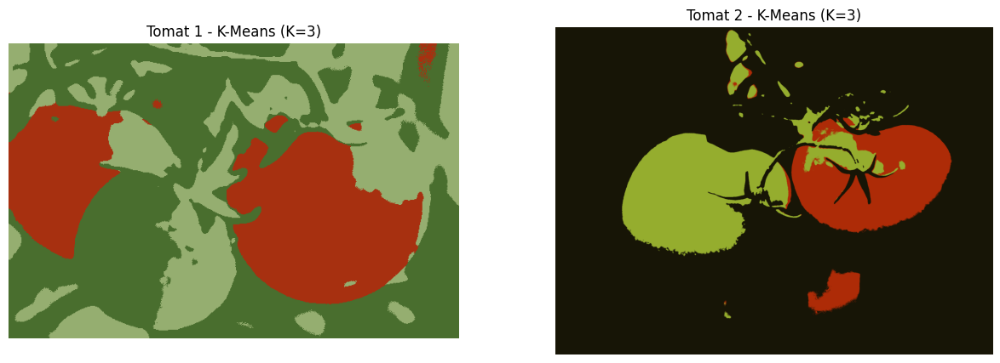

In [ ]:
def segment_kmeans(image, k=3):
    pixel_values = image.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

    _, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)

    segmented_image = centers[labels.flatten()]
    segmented_image = segmented_image.reshape(image.shape)

    return segmented_image

# Set K=3 untuk memisahkan: (1) Latar Gelap, (2) Tomat Merah, (3) Tomat/Bagian Hijau
segmented_kmeans_tomat1 = segment_kmeans(combined_tomat1, k=3)
segmented_kmeans_tomat2 = segment_kmeans(combined_tomat2, k=3)

show_images(['Tomat 1 - K-Means (K=3)', 'Tomat 2 - K-Means (K=3)'], [segmented_kmeans_tomat1, segmented_kmeans_tomat2])

## Edge-Based Segmentation (Canny)

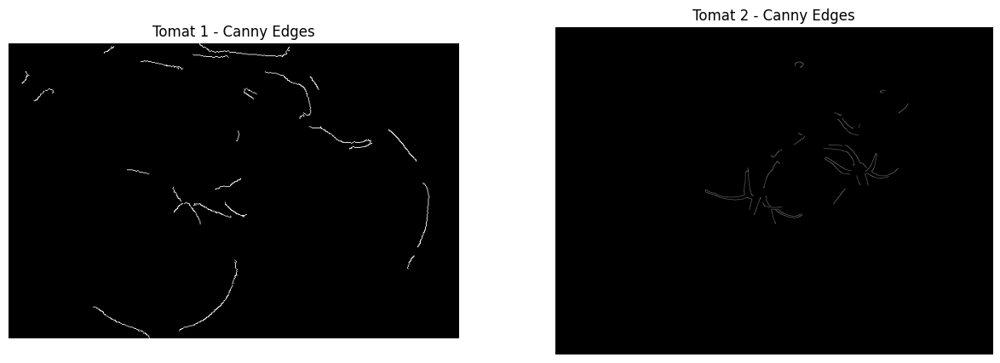

In [ ]:
# Canny edge detector membutuhkan citra grayscale
gray_tomat1 = cv2.cvtColor(combined_tomat1, cv2.COLOR_RGB2GRAY)
gray_tomat2 = cv2.cvtColor(combined_tomat2, cv2.COLOR_RGB2GRAY)

edges_tomat1 = cv2.Canny(gray_tomat1, 50, 150)
edges_tomat2 = cv2.Canny(gray_tomat2, 50, 150)

show_images(['Tomat 1 - Canny Edges', 'Tomat 2 - Canny Edges'], [edges_tomat1, edges_tomat2])

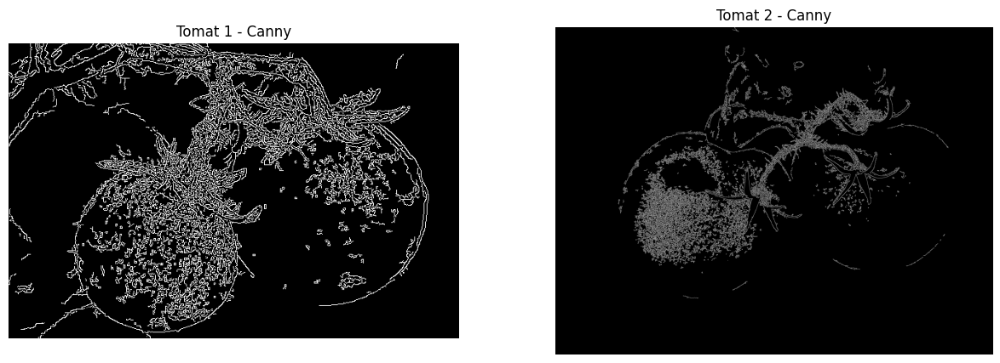

In [ ]:
# 17x17
gray_tomat1_asli = cv2.cvtColor(img_tomat1, cv2.COLOR_RGB2GRAY)
gray_tomat2_asli = cv2.cvtColor(img_tomat2, cv2.COLOR_RGB2GRAY)

edges_tomat1_baru = cv2.Canny(gray_tomat1_asli, 30, 100)
edges_tomat2_baru = cv2.Canny(gray_tomat2_asli, 30, 100)

show_images(['Tomat 1 - Canny', 'Tomat 2 - Canny'], [edges_tomat1_baru, edges_tomat2_baru])

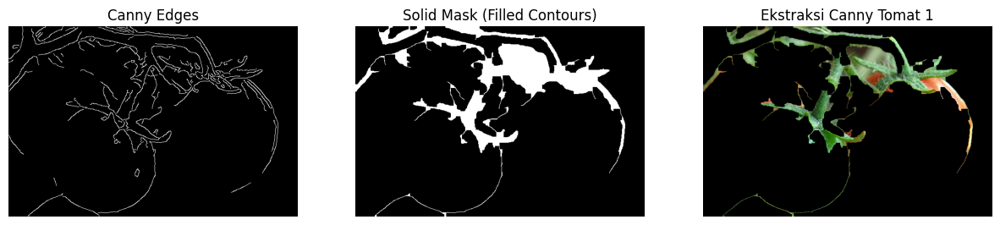

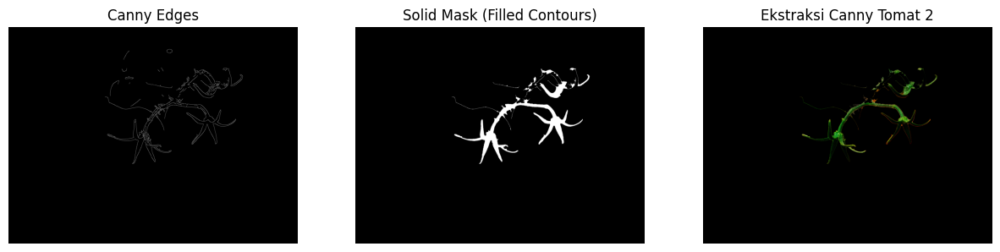

In [ ]:
import cv2
import numpy as np

# --- SEGMENTASI BERBASIS TEPI (CANNY + CONTOUR FILLING) ---

# 1. Gunakan gambar asli dan konversi ke Grayscale
gray_tomat1 = cv2.cvtColor(img_tomat1, cv2.COLOR_RGB2GRAY)
gray_tomat2 = cv2.cvtColor(img_tomat2, cv2.COLOR_RGB2GRAY)

# 2. Gaussian Blur (Eksplorasi Parameter: Kernel 9x9)
# Blur harus cukup kuat untuk menghilangkan tekstur dalam kulit tomat,
# tapi tidak terlalu kuat agar batas luar tomat tidak hilang.
blur_tomat1 = cv2.GaussianBlur(gray_tomat1, (9, 9), 0)
blur_tomat2 = cv2.GaussianBlur(gray_tomat2, (9, 9), 0)

# 3. Canny Edge Detection (Eksplorasi Double Thresholding: 30 dan 100)
edges_tomat1 = cv2.Canny(blur_tomat1, 30, 100)
edges_tomat2 = cv2.Canny(blur_tomat2, 30, 100)

def buat_mask_dari_tepi(edges):
    # 4. Morfologi Dilation: Menebalkan garis tepi agar garis yang terputus bisa menyambung
    kernel_dilate = np.ones((5, 5), np.uint8)
    edges_dilated = cv2.dilate(edges, kernel_dilate, iterations=2)

    # 5. Mencari Kontur (Garis batas)
    # RETR_EXTERNAL sangat penting: hanya mengambil garis batas paling LUAR
    # dan mengabaikan semua garis berantakan di dalam objek
    contours, _ = cv2.findContours(edges_dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 6. Menyiapkan kanvas mask hitam kosong
    mask = np.zeros_like(edges)

    # 7. Mengisi (Fill) bagian dalam batas kontur menjadi putih solid
    for cnt in contours:
        area = cv2.contourArea(cnt)
        # Eksplorasi Parameter Luas: Abaikan kontur/garis kecil di bawah 2000 piksel (noise background)
        if area > 2000:
            cv2.drawContours(mask, [cnt], -1, 255, cv2.FILLED)

    # Kembalikan tepi mask menjadi normal (menghilangkan sisa ketebalan dari efek Dilation)
    mask = cv2.erode(mask, kernel_dilate, iterations=2)
    return mask

# Terapkan fungsi pembuat mask solid
mask_solid_tomat1 = buat_mask_dari_tepi(edges_tomat1)
mask_solid_tomat2 = buat_mask_dari_tepi(edges_tomat2)

# 8. Ekstraksi gambar asli (Membuang background)
ekstraksi_canny_tomat1 = cv2.bitwise_and(img_tomat1, img_tomat1, mask=mask_solid_tomat1)
ekstraksi_canny_tomat2 = cv2.bitwise_and(img_tomat2, img_tomat2, mask=mask_solid_tomat2)

# Visualisasi Tomat 1
show_images(['Canny Edges', 'Solid Mask (Filled Contours)', 'Ekstraksi Canny Tomat 1'],
            [edges_tomat1, mask_solid_tomat1, ekstraksi_canny_tomat1], figsize=(15, 5))

# Visualisasi Tomat 2
show_images(['Canny Edges', 'Solid Mask (Filled Contours)', 'Ekstraksi Canny Tomat 2'],
            [edges_tomat2, mask_solid_tomat2, ekstraksi_canny_tomat2], figsize=(15, 5))

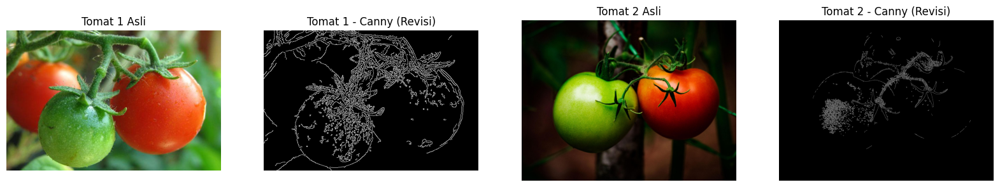

In [ ]:
# Canny Edge Detector: Multitahap (Noise reduction -> Gradient -> NMS -> Double Thresholding)

# 1. Gunakan Grayscale dari gambar asli
gray_tomat1_asli = cv2.cvtColor(img_tomat1, cv2.COLOR_RGB2GRAY)
gray_tomat2_asli = cv2.cvtColor(img_tomat2, cv2.COLOR_RGB2GRAY)

# 2. Noise Reduction: Berikan blur yang SANGAT KECIL (3x3) hanya agar bintik derau hilang
blur_tipis_tomat1 = cv2.GaussianBlur(gray_tomat1_asli, (3, 3), 0)
blur_tipis_tomat2 = cv2.GaussianBlur(gray_tomat2_asli, (3, 3), 0)

# 3. EKSPLORASI DOUBLE THRESHOLDING
# Ambang bawah (low) = 30: tepi lemah dipertahankan jika terhubung
# Ambang atas (high) = 90: piksel dengan gradien > 90 pasti dianggap tepi
edges_tomat1 = cv2.Canny(blur_tipis_tomat1, 30, 90)
edges_tomat2 = cv2.Canny(blur_tipis_tomat2, 30, 90)

show_images(['Tomat 1 Asli', 'Tomat 1 - Canny (Revisi)', 'Tomat 2 Asli', 'Tomat 2 - Canny (Revisi)'],
            [img_tomat1, edges_tomat1, img_tomat2, edges_tomat2], figsize=(20, 5))

# Komparasi

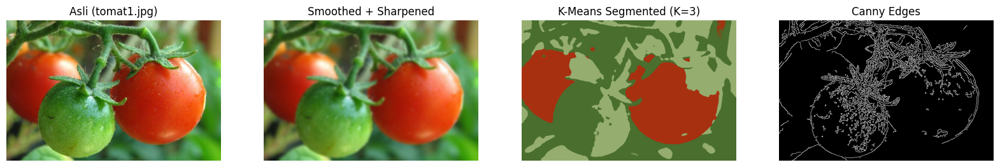

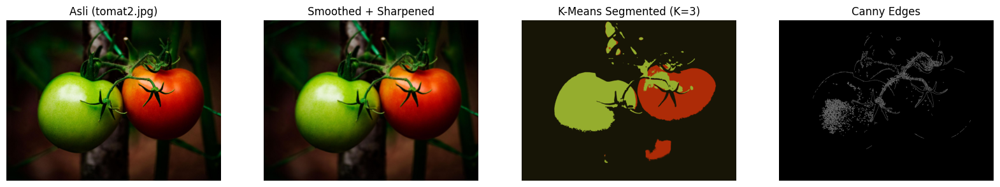

In [ ]:
show_images(
    ['Asli (tomat1.jpg)', 'Smoothed + Sharpened', 'K-Means Segmented (K=3)', 'Canny Edges'],
    [img_tomat1, combined_tomat1, segmented_kmeans_tomat1, edges_tomat1],
    figsize=(20, 5)
)

show_images(
    ['Asli (tomat2.jpg)', 'Smoothed + Sharpened', 'K-Means Segmented (K=3)', 'Canny Edges'],
    [img_tomat2, combined_tomat2, segmented_kmeans_tomat2, edges_tomat2],
    figsize=(20, 5)
)

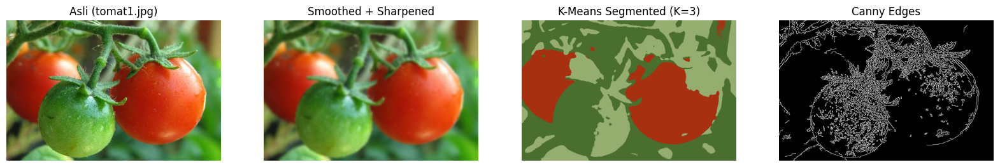

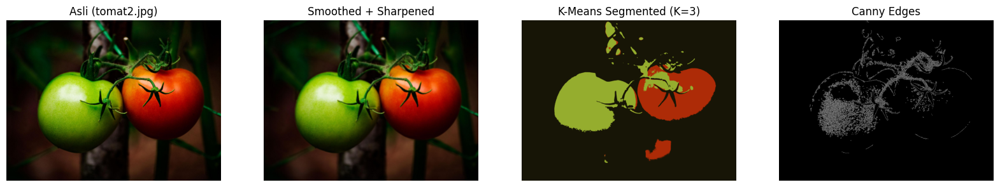

In [ ]:
show_images(
    ['Asli (tomat1.jpg)', 'Smoothed + Sharpened', 'K-Means Segmented (K=3)', 'Canny Edges'],
    [img_tomat1, combined_tomat1, segmented_kmeans_tomat1, edges_tomat1_baru],
    figsize=(20, 5)
)

show_images(
    ['Asli (tomat2.jpg)', 'Smoothed + Sharpened', 'K-Means Segmented (K=3)', 'Canny Edges'],
    [img_tomat2, combined_tomat2, segmented_kmeans_tomat2, edges_tomat2_baru],
    figsize=(20, 5)
)

# EKSTRAKSI (MASKING) DARI K-MEANS

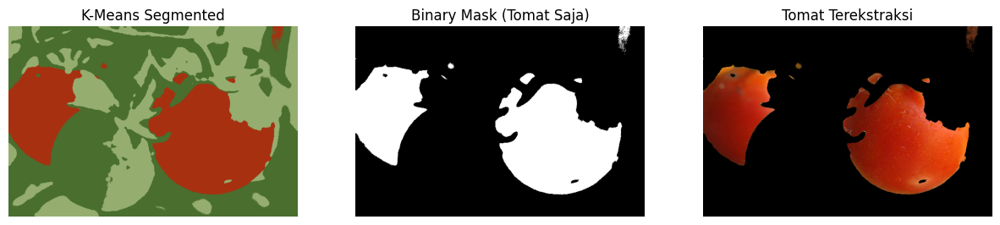

In [ ]:
pixels = segmented_kmeans_tomat1.reshape(-1, 3)
colors = np.unique(pixels, axis=0)
indeks_merah = np.argmax(colors[:, 0])
warna_tomat = colors[indeks_merah]

mask_tomat_final = cv2.inRange(segmented_kmeans_tomat1, warna_tomat, warna_tomat)

tomat_terekstraksi_final = cv2.bitwise_and(img_tomat1, img_tomat1, mask=mask_tomat_final)

show_images(['K-Means Segmented', 'Binary Mask (Tomat Saja)', 'Tomat Terekstraksi'],
            [segmented_kmeans_tomat1, mask_tomat_final, tomat_terekstraksi_final],
            figsize=(15, 5))

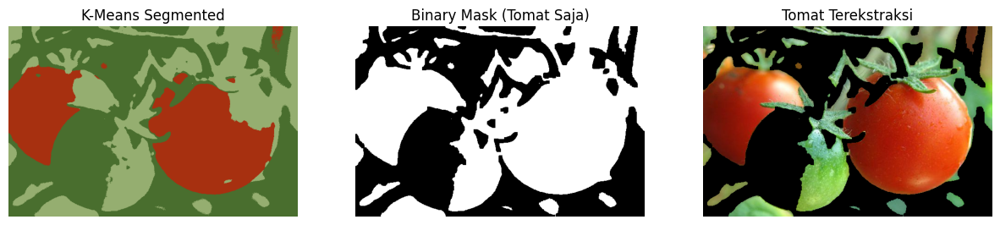

In [ ]:
# Ubah citra K-Means menjadi daftar piksel 2D dan cari warna uniknya
pixels = segmented_kmeans_tomat1.reshape(-1, 3)
colors = np.unique(pixels, axis=0)

# 1. Identifikasi klaster Tomat Merah (Saluran Red / indeks 0 tertinggi)
indeks_merah = np.argmax(colors[:, 0])
warna_merah = colors[indeks_merah]

# 2. Identifikasi klaster Tomat Hijau & Pantulan Cahaya (Saluran Green / indeks 1 tertinggi)
indeks_hijau = np.argmax(colors[:, 1])
warna_hijau = colors[indeks_hijau]

# 3. Buat mask untuk masing-masing target warna
mask_merah = cv2.inRange(segmented_kmeans_tomat1, warna_merah, warna_merah)
mask_hijau = cv2.inRange(segmented_kmeans_tomat1, warna_hijau, warna_hijau)

# 4. Gabungkan mask merah dan hijau menggunakan logika OR
mask_tomat_final = cv2.bitwise_or(mask_merah, mask_hijau)

# 5. Operasi Morfologi Closing untuk menambal sisa lubang kecil/noise di badan tomat
kernel_morph = np.ones((7, 7), np.uint8)
mask_tomat_final = cv2.morphologyEx(mask_tomat_final, cv2.MORPH_CLOSE, kernel_morph)

# 6. Ekstraksi objek menggunakan bitwise_and
tomat_terekstraksi_final = cv2.bitwise_and(img_tomat1, img_tomat1, mask=mask_tomat_final)

# Tampilkan Hasil
show_images(['K-Means Segmented', 'Binary Mask (Tomat Saja)', 'Tomat Terekstraksi'],
            [segmented_kmeans_tomat1, mask_tomat_final, tomat_terekstraksi_final],
            figsize=(15, 5))

# Otsu Thresholding

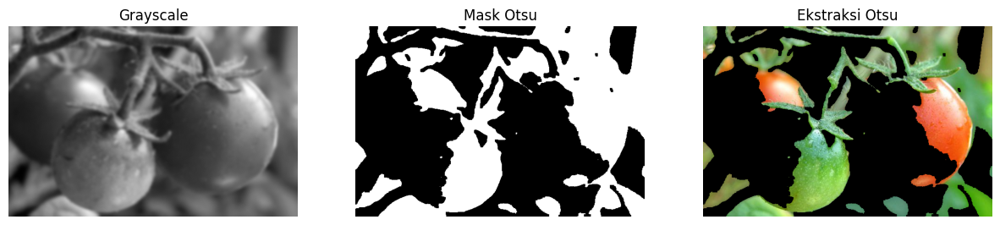

In [ ]:
gray_tomat1 = cv2.cvtColor(combined_tomat1, cv2.COLOR_RGB2GRAY)

_, mask_otsu_tomat1 = cv2.threshold(gray_tomat1, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel_morph = np.ones((5,5), np.uint8)
mask_otsu_tomat1 = cv2.morphologyEx(mask_otsu_tomat1, cv2.MORPH_CLOSE, kernel_morph)

tomat_terekstraksi_otsu = cv2.bitwise_and(img_tomat1, img_tomat1, mask=mask_otsu_tomat1)

show_images(['Grayscale', 'Mask Otsu', 'Ekstraksi Otsu'],
            [gray_tomat1, mask_otsu_tomat1, tomat_terekstraksi_otsu],
            figsize=(15, 5))

# HSV Color Thresholding

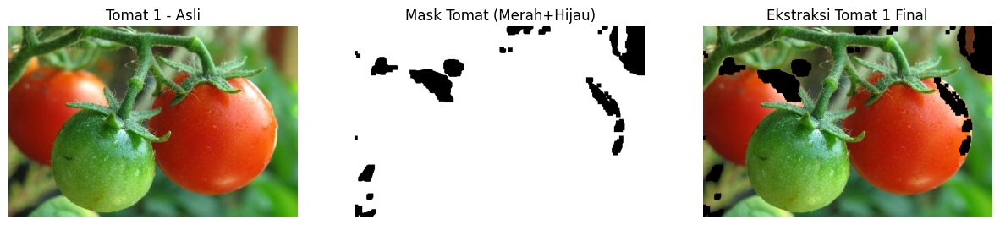

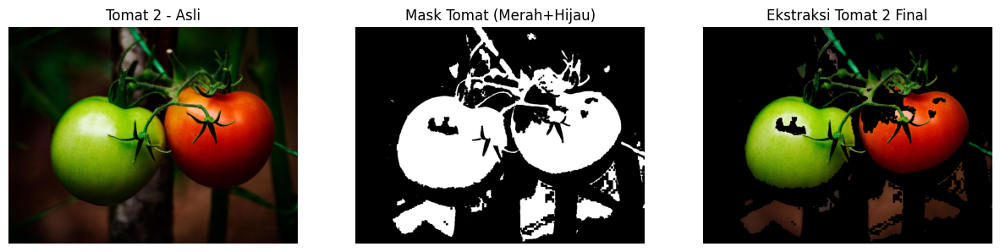

In [ ]:
def segmentasi_tomat_hsv(image_rgb):
    hsv_image = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)

    lower_red1 = np.array([0, 70, 50])
    upper_red1 = np.array([10, 255, 255])
    lower_red2 = np.array([160, 70, 50])
    upper_red2 = np.array([180, 255, 255])

    mask_red1 = cv2.inRange(hsv_image, lower_red1, upper_red1)
    mask_red2 = cv2.inRange(hsv_image, lower_red2, upper_red2)
    mask_red = cv2.bitwise_or(mask_red1, mask_red2)

    lower_green = np.array([30, 50, 50])
    upper_green = np.array([85, 255, 255])
    mask_green = cv2.inRange(hsv_image, lower_green, upper_green)

    mask_gabungan = cv2.bitwise_or(mask_red, mask_green)

    kernel = np.ones((9, 9), np.uint8)
    mask_final = cv2.morphologyEx(mask_gabungan, cv2.MORPH_CLOSE, kernel)

    tomat_terekstraksi = cv2.bitwise_and(image_rgb, image_rgb, mask=mask_final)

    return mask_final, tomat_terekstraksi

mask_tomat1, hasil_tomat1 = segmentasi_tomat_hsv(img_tomat1)
mask_tomat2, hasil_tomat2 = segmentasi_tomat_hsv(img_tomat2)

show_images(['Tomat 1 - Asli', 'Mask Tomat (Merah+Hijau)', 'Ekstraksi Tomat 1 Final'],
            [img_tomat1, mask_tomat1, hasil_tomat1],
            figsize=(15, 5))

show_images(['Tomat 2 - Asli', 'Mask Tomat (Merah+Hijau)', 'Ekstraksi Tomat 2 Final'],
            [img_tomat2, mask_tomat2, hasil_tomat2],
            figsize=(15, 5))

# Segmentasi Final

## 1. Import & Konfigurasi

In [6]:
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

NAMES = ['tomat1', 'tomat2']
MAX_SIDE = 800
CFG = {
    'tomat1': dict(ch='a',      inv=True,  T=105),
    'tomat2': dict(ch='chroma', inv=False, T=45),
}

## 2. Ground Truth

In [7]:
def gt_dari_mask(path, thr=8, hole_frac=0.002, min_frac=0.001):
    m = cv2.imread(path).max(axis=2)
    fg = (m > thr).astype(np.uint8) * 255
    h, w = fg.shape
    n, lab, st, _ = cv2.connectedComponentsWithStats(fg)
    keep = np.zeros_like(fg)
    for i in range(1, n):
        if st[i, 4] >= min_frac * h * w: keep[lab == i] = 255
    n, lab, st, _ = cv2.connectedComponentsWithStats(255 - keep)
    for i in range(1, n):
        x, y, ww, hh, a = st[i]
        menyentuh_tepi = x == 0 or y == 0 or x + ww == w or y + hh == h
        if (not menyentuh_tepi) and a < hole_frac * h * w: keep[lab == i] = 255
    return keep

## 3. Menyelaraskan Mask dengan Foto Asli

In [8]:
def selaraskan(foto_path, mask_path, gt):
    o = cv2.imread(foto_path); m = cv2.imread(mask_path)
    so, sm = 800 / o.shape[1], 800 / m.shape[1]
    o_s = cv2.resize(o, None, fx=so, fy=so); m_s = cv2.resize(m, None, fx=sm, fy=sm)
    sift = cv2.SIFT_create(4000)
    g1 = cv2.cvtColor(m_s, cv2.COLOR_BGR2GRAY); g2 = cv2.cvtColor(o_s, cv2.COLOR_BGR2GRAY)
    k1, d1 = sift.detectAndCompute(g1, (g1 > 8).astype(np.uint8) * 255)
    k2, d2 = sift.detectAndCompute(g2, None)
    cocok = [a for a, b in cv2.BFMatcher().knnMatch(d1, d2, k=2) if a.distance < 0.7 * b.distance]
    src = np.float32([k1[c.queryIdx].pt for c in cocok]); dst = np.float32([k2[c.trainIdx].pt for c in cocok])
    M, _ = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=4)
    M3 = np.diag([1 / so, 1 / so, 1.0]) @ np.vstack([M, [0, 0, 1]]) @ np.diag([sm, sm, 1.0])
    gt_w = cv2.warpAffine(gt, M3[:2], (o.shape[1], o.shape[0]), flags=cv2.INTER_NEAREST)
    return o, gt_w

def siapkan(name):
    o, g = selaraskan(f'{name}.jpg', f'mask_{name}.png', gt_dari_mask(f'mask_{name}.png'))
    s = MAX_SIDE / max(o.shape[:2])
    if s < 1:
        o = cv2.resize(o, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        g = cv2.resize(g, (o.shape[1], o.shape[0]), interpolation=cv2.INTER_NEAREST)
    return o, (g > 127).astype(np.uint8) * 255

DATA = {n: siapkan(n) for n in NAMES}

### Cek keselarasan (garis kuning harus menempel di tepi tomat)

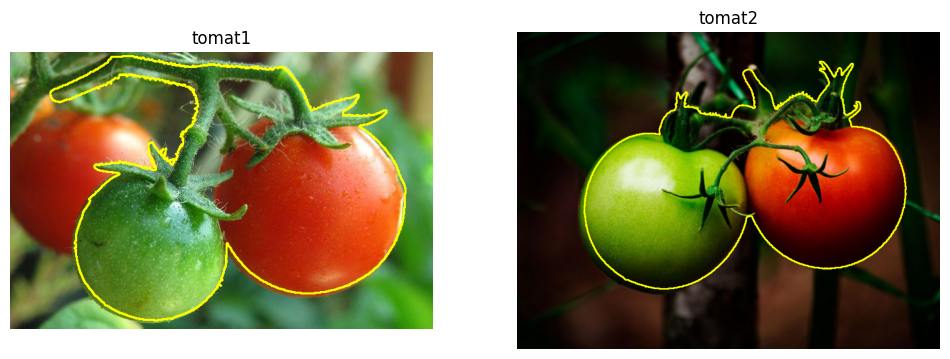

In [9]:
plt.figure(figsize=(12, 5))
for i, (n, (img, gt)) in enumerate(DATA.items()):
    vis = img.copy()
    cnts, _ = cv2.findContours(gt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnts, -1, (0, 255, 255), 2)
    plt.subplot(1, 2, i + 1); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.title(n); plt.axis('off')
plt.show()

## 4. Preprocessing & Post-processing
- Gaussian Blur untuk meredam noise.
- Ruang warna Lab: channel a* (kemerahan) dan chroma (kepekatan warna).
- Morfologi (opening, closing) untuk membuang bintik dan menutup lubang, lalu isi kontur.

In [10]:
def channels(img):
    b = cv2.GaussianBlur(img, (5, 5), 0)
    lab = cv2.cvtColor(b, cv2.COLOR_BGR2LAB)
    chroma = np.clip(np.hypot(lab[:, :, 1].astype(float) - 128, lab[:, :, 2].astype(float) - 128) * 2, 0, 255).astype(np.uint8)
    return b, lab, {'a': lab[:, :, 1], 'chroma': chroma}

def rapikan(mask, k_frac=0.012, min_frac=0.01):
    h, w = mask.shape
    k = max(3, int(round(k_frac * min(h, w)))) | 1
    K = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    m = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K); m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, K)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(m)
    for c in cnts:
        if cv2.contourArea(c) >= min_frac * h * w: cv2.drawContours(out, [c], -1, 255, cv2.FILLED)
    return out

## 5. Metode Segmentasi
### 5a. Otsu (threshold otomatis pada satu channel)
### 5b. Threshold Global (T dipilih manual)
### 5c. K-Means (cluster paling merah = tomat)
### 5d. Canny (tepi -> kontur -> isi)

In [11]:
def seg_otsu(img, name):
    _, _, ch = channels(img); c = CFG[name]
    flag = cv2.THRESH_BINARY_INV if c['inv'] else cv2.THRESH_BINARY
    _, m = cv2.threshold(ch[c['ch']], 0, 255, flag + cv2.THRESH_OTSU)
    return rapikan(m)

def seg_threshold(img, name):
    _, _, ch = channels(img); c = CFG[name]
    m = (ch[c['ch']] <= c['T']) if c['inv'] else (ch[c['ch']] > c['T'])
    return rapikan(m.astype(np.uint8) * 255)

def seg_kmeans(img, name, k=4):
    b, lab, _ = channels(img)
    Z = np.float32(lab.reshape(-1, 3)); cv2.setRNGSeed(0)
    _, lb, ct = cv2.kmeans(Z, k, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2), 10, cv2.KMEANS_PP_CENTERS)
    return rapikan((lb.reshape(img.shape[:2]) == np.argmax(ct[:, 1])).astype(np.uint8) * 255)

def seg_canny(img, name, low=30, high=100):
    g = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (9, 9), 0)
    e = cv2.dilate(cv2.Canny(g, low, high), np.ones((5, 5), np.uint8), iterations=2)
    cnts, _ = cv2.findContours(e, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    m = np.zeros(g.shape, np.uint8); cv2.drawContours(m, cnts, -1, 255, cv2.FILLED)
    return rapikan(m)

## 6. Metrik IoU dan Perbandingan Metode
IoU = |Prediksi ∩ GT| / |Prediksi ∪ GT|

In [12]:
def iou(p, g):
    p, g = p > 0, g > 0
    u = (p | g).sum(); return (p & g).sum() / u if u else 0.0

METODE = {'Otsu': seg_otsu, 'Threshold global': seg_threshold, 'K-Means': seg_kmeans, 'Canny': seg_canny}
hasil, rows = {}, []
for n, (img, gt) in DATA.items():
    for mn, fn in METODE.items():
        m = fn(img, n); hasil[(n, mn)] = m
        rows.append({'Gambar': n, 'Metode': mn, 'IoU': round(iou(m, gt), 4)})
tabel = pd.DataFrame(rows).pivot(index='Metode', columns='Gambar', values='IoU')
tabel['Rata-rata'] = tabel.mean(axis=1).round(4)
tabel.sort_values('Rata-rata', ascending=False)

Gambar,tomat1,tomat2,Rata-rata
Metode,,,
Threshold global,0.6475,0.7249,0.6862
Otsu,0.5308,0.6317,0.5812
Canny,0.2871,0.2506,0.2689
K-Means,0.2979,0.1932,0.2456


### Visualisasi mask tiap metode

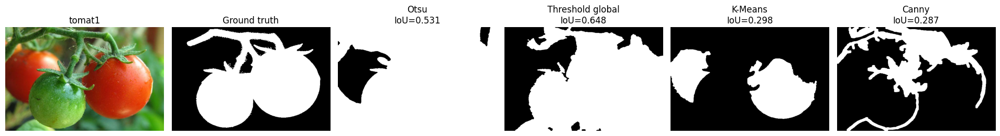

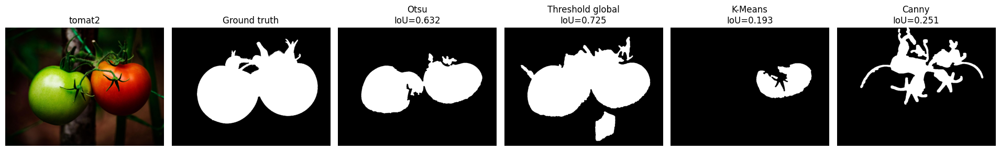

In [13]:
for n, (img, gt) in DATA.items():
    plt.figure(figsize=(3.2 * (len(METODE) + 2), 3.6))
    plt.subplot(1, len(METODE) + 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title(n); plt.axis('off')
    plt.subplot(1, len(METODE) + 2, 2); plt.imshow(gt, cmap='gray'); plt.title('Ground truth'); plt.axis('off')
    for i, mn in enumerate(METODE):
        m = hasil[(n, mn)]
        plt.subplot(1, len(METODE) + 2, i + 3); plt.imshow(m, cmap='gray')
        plt.title(f'{mn}\nIoU={iou(m, gt):.3f}'); plt.axis('off')
    plt.tight_layout(); plt.show()

## 7. Hasil Akhir: Tomat dengan Background Dihapus (metode terbaik)

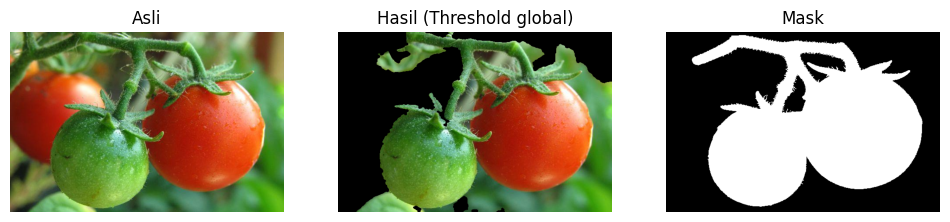

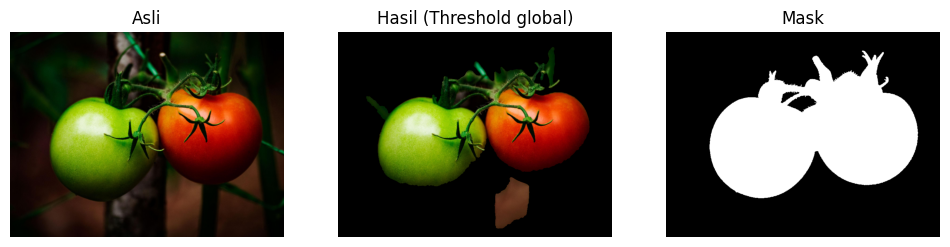

In [15]:
TERBAIK = 'Threshold global'
for n, (img, gt) in DATA.items():
    m = hasil[(n, TERBAIK)]
    hitam = cv2.bitwise_and(img, img, mask=m)
    cv2.imwrite(f'hasil_{n}.png', hitam)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title('Asli'); plt.axis('off')
    plt.subplot(1, 3, 2); plt.imshow(cv2.cvtColor(hitam, cv2.COLOR_BGR2RGB)); plt.title(f'Hasil ({TERBAIK})'); plt.axis('off')
    plt.subplot(1, 3, 3); plt.imshow(gt, cmap='gray'); plt.title('Mask'); plt.axis('off')
    plt.show()